In [1]:
import os
import sys
import time
import shutil
import subprocess
import platform
from pathlib import Path

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

In [2]:
print("=" * 65)
print("1. CREATING VISIONPORT PROJECT REPOSITORY")
print("=" * 65)

PROJECT_DIR = Path("/content/VisionPort")

# Clean up any existing repository directory to prevent conflicting Git states
if PROJECT_DIR.exists():
    shutil.rmtree(PROJECT_DIR)

PROJECT_DIR.mkdir(exist_ok=True)

folders = [
    "app",
    "models",
    "inference",
    "preprocessing",
    "tests",
    "outputs",
    "docs"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(exist_ok=True)

print("Project repository created successfully!")

print("\nProject Structure:")
for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(str(PROJECT_DIR), "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

1. CREATING VISIONPORT PROJECT REPOSITORY
Project repository created successfully!

Project Structure:
VisionPort/
  app/
  models/
  outputs/
  inference/
  docs/
  tests/
  preprocessing/


In [3]:
readme = """
# VisionPort - Deep Learning Inference Platform

## Description
VisionPort is an end-to-end deep learning inference platform.

## Architecture
Client -> FastAPI -> Preprocessing -> Triton/TensorRT
-> PyTorch Model -> GPU -> Prediction Response

## Technologies
- Python
- PyTorch
- CUDA
- FastAPI
- NVIDIA GPU
- Git and GitHub

## Project Modules
- app: API application
- models: Deep learning models
- inference: Model execution
- preprocessing: Input processing
- tests: Testing modules
- outputs: Results
- docs: Documentation
"""

model_code = '''
import torch
import torch.nn as nn

class VisionPortCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(32, 10)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)
'''

(PROJECT_DIR / "README.md").write_text(readme)
(PROJECT_DIR / "models" / "model.py").write_text(model_code)
(PROJECT_DIR / "requirements.txt").write_text(
    "torch\nmatplotlib\nfastapi\n"
)

(PROJECT_DIR / ".gitignore").write_text(
    "__pycache__/\n*.pyc\n.env\noutputs/*.pt\n"
)

print("\nProject files created:")
for file in PROJECT_DIR.rglob("*"):
    if file.is_file():
        print(" -", file.relative_to(PROJECT_DIR))


Project files created:
 - .gitignore
 - requirements.txt
 - README.md
 - models/model.py


In [4]:
print("\n" + "=" * 65)
print("2. GIT VERSION CONTROL WORKFLOW")
print("=" * 65)

def git(command):
    result = subprocess.run(
        ["git"] + command,
        cwd=PROJECT_DIR,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(result.stderr)

    return result.stdout.strip()

# Configure globally first so git does not block the commits
subprocess.run(["git", "config", "--global", "user.name", "VisionPort Student"])
subprocess.run(["git", "config", "--global", "user.email", "student@example.com"])

git(["init", "-b", "main"])

git(["add", "."])
git(["commit", "-m", "Initial VisionPort project setup"])

print("\nInitial Commit Created!")
print(git(["log", "--oneline"]))

# Create a feature branch
git(["switch", "-c", "feature/environment-setup"])

(PROJECT_DIR / "docs" / "environment.txt").write_text(
    "VisionPort Development Environment\n"
    "Framework: PyTorch\n"
    "Hardware: CPU/CUDA GPU\n"
    "Version Control: Git\n"
)

git(["add", "."])
print("\nStaged Changes:")
print(git(["diff", "--cached", "--stat"]))

git(["commit", "-m", "Add development environment documentation"])

print("\nFeature Branch Commit:")
print(git(["log", "--oneline"]))

# Merge feature branch into main
git(["switch", "main"])
git(["merge", "--no-ff", "feature/environment-setup",
     "-m", "Merge environment setup"])

print("\nFinal Git Branches:")
print(git(["branch"]))

print("\nFinal Git History:")
print(git(["log", "--oneline", "--graph", "--all"]))


2. GIT VERSION CONTROL WORKFLOW

Initial Commit Created!
a82e259 Initial VisionPort project setup

Staged Changes:
docs/environment.txt | 4 ++++
 1 file changed, 4 insertions(+)

Feature Branch Commit:
7d5f519 Add development environment documentation
a82e259 Initial VisionPort project setup

Final Git Branches:
feature/environment-setup
* main

Final Git History:
*   0ae4e94 Merge environment setup
|\  
| * 7d5f519 Add development environment documentation
|/  
* a82e259 Initial VisionPort project setup


In [5]:
print("\n" + "=" * 65)
print("3. PYTORCH AND CUDA ENVIRONMENT")
print("=" * 65)

print("Python Version:", sys.version.split()[0])
print("Operating System:", platform.system())
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

gpu_available = torch.cuda.is_available()

if gpu_available:
    device = torch.device("cuda")

    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("GPU Count:", torch.cuda.device_count())

    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory
                / (1024 ** 3), 2), "GB")
else:
    device = torch.device("cpu")
    print("GPU not available. Running using CPU.")

print("Selected Device:", device)


3. PYTORCH AND CUDA ENVIRONMENT
Python Version: 3.13.18
Operating System: Linux
PyTorch Version: 2.14.1+cpu
CUDA Available: False
GPU not available. Running using CPU.
Selected Device: cpu


In [6]:
print("\n" + "=" * 65)
print("4. CNN MODEL EXECUTION")
print("=" * 65)

class VisionPortCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(32, 10)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


model = VisionPortCNN().to(device)
model.eval()

# Simulated image batch
sample_input = torch.randn(8, 3, 64, 64).to(device)

with torch.no_grad():
    prediction = model(sample_input)

print("Model:", model.__class__.__name__)
print("Input Shape:", tuple(sample_input.shape))
print("Output Shape:", tuple(prediction.shape))
print("Number of Parameters:",
      sum(p.numel() for p in model.parameters()))

predicted_classes = torch.argmax(prediction, dim=1)

print("Predicted Classes:", predicted_classes.cpu().tolist())

# Save model inside repository
torch.save(model.state_dict(),
           PROJECT_DIR / "outputs" / "visionport_model.pth")

print("Model saved successfully!")


4. CNN MODEL EXECUTION
Model: VisionPortCNN
Input Shape: (8, 3, 64, 64)
Output Shape: (8, 10)
Number of Parameters: 5418
Predicted Classes: [7, 7, 7, 7, 7, 7, 7, 7]
Model saved successfully!


In [7]:
print("\n" + "=" * 65)
print("5. CPU VS GPU PERFORMANCE BENCHMARK")
print("=" * 65)

def benchmark(device, iterations=20):

    benchmark_model = VisionPortCNN().to(device)
    benchmark_model.eval()

    data = torch.randn(8, 3, 64, 64).to(device)

    with torch.no_grad():

        # Warm-up
        for _ in range(5):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(iterations):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()

    return ((end - start) / iterations) * 1000


cpu_time = benchmark(torch.device("cpu"))

times = {"CPU": cpu_time}

print(f"CPU Average Time: {cpu_time:.4f} ms")

if gpu_available:

    gpu_time = benchmark(torch.device("cuda"))
    times["CUDA GPU"] = gpu_time

    print(f"GPU Average Time: {gpu_time:.4f} ms")

    if gpu_time > 0:
        print("Measured Speedup:",
              f"{cpu_time / gpu_time:.2f}x")
else:
    print("CUDA benchmark skipped because GPU is unavailable.")


5. CPU VS GPU PERFORMANCE BENCHMARK
CPU Average Time: 11.6010 ms
CUDA benchmark skipped because GPU is unavailable.



6. GRAPHICAL OUTPUTS


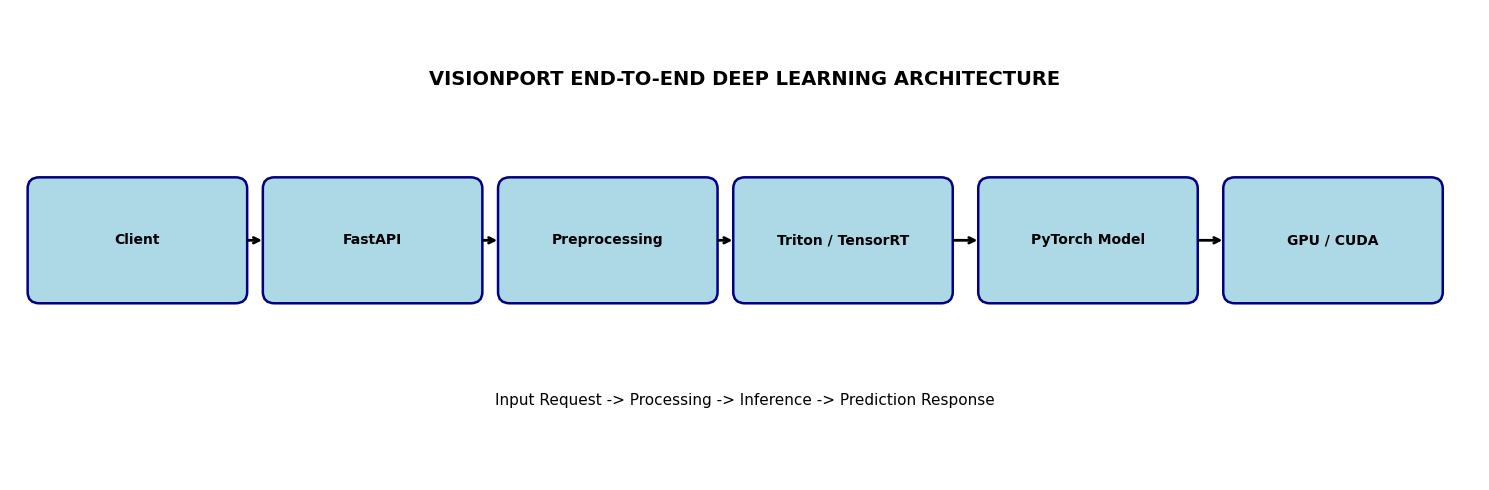

In [8]:
print("\n" + "=" * 65)
print("6. GRAPHICAL OUTPUTS")
print("=" * 65)

fig, ax = plt.subplots(figsize=(15, 5))

ax.set_xlim(0, 15)
ax.set_ylim(0, 5)
ax.axis("off")

architecture = [
    ("Client", 0.3),
    ("FastAPI", 2.7),
    ("Preprocessing", 5.1),
    ("Triton / TensorRT", 7.5),
    ("PyTorch Model", 10.0),
    ("GPU / CUDA", 12.5)
]

for label, x in architecture:

    box = FancyBboxPatch(
        (x, 2), 2, 1.1,
        boxstyle="round,pad=0.12",
        linewidth=1.8,
        edgecolor="navy",
        facecolor="lightblue"
    )

    ax.add_patch(box)

    ax.text(x + 1, 2.55, label,
            ha="center", va="center",
            fontsize=10, fontweight="bold")

for i in range(len(architecture) - 1):

    x1 = architecture[i][1] + 2
    x2 = architecture[i + 1][1]

    ax.annotate(
        "",
        xy=(x2 - 0.1, 2.55),
        xytext=(x1 + 0.1, 2.55),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.text(7.5, 4.2,
        "VISIONPORT END-TO-END DEEP LEARNING ARCHITECTURE",
        ha="center", fontsize=14, fontweight="bold")

ax.text(7.5, 0.8,
        "Input Request -> Processing -> Inference -> Prediction Response",
        ha="center", fontsize=11)

plt.tight_layout()
plt.show()

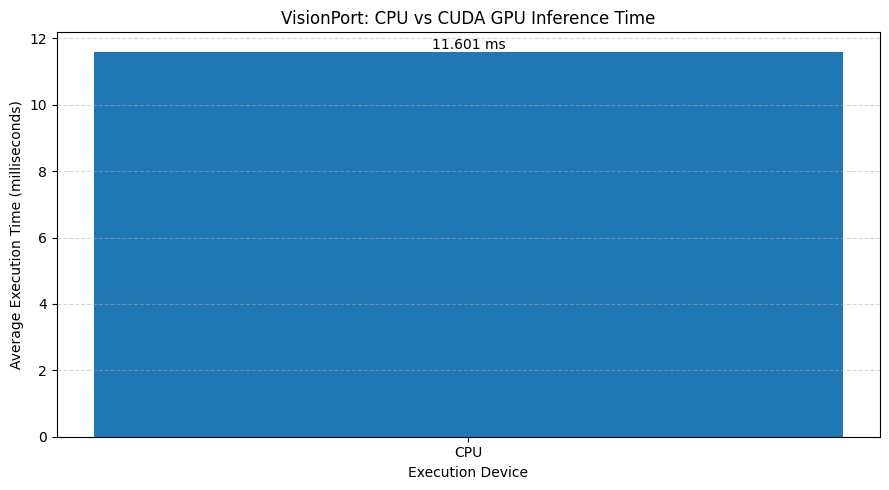

In [9]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    list(times.keys()),
    list(times.values())
)

plt.title("VisionPort: CPU vs CUDA GPU Inference Time")
plt.xlabel("Execution Device")
plt.ylabel("Average Execution Time (milliseconds)")
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar, value in zip(bars, times.values()):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

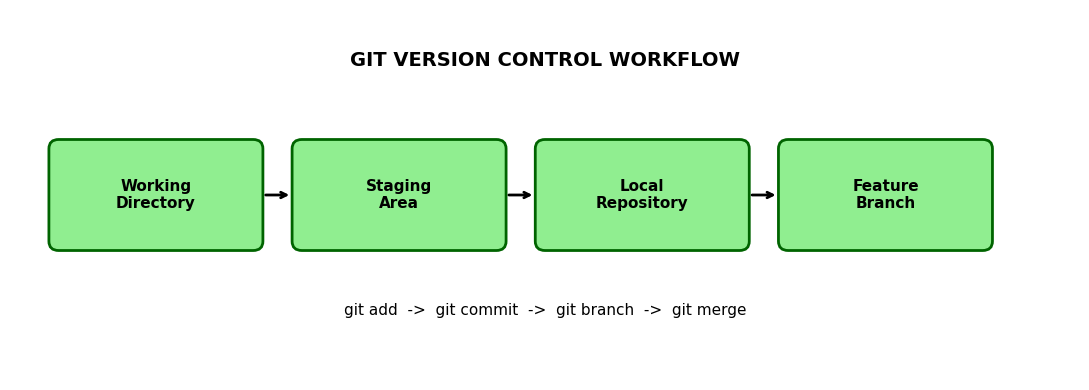

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.set_xlim(0, 11)
ax.set_ylim(0, 4)
ax.axis("off")

git_steps = [
    ("Working\nDirectory", 0.5),
    ("Staging\nArea", 3.0),
    ("Local\nRepository", 5.5),
    ("Feature\nBranch", 8.0)
]

for label, x in git_steps:

    box = FancyBboxPatch(
        (x, 1.5), 2, 1,
        boxstyle="round,pad=0.1",
        facecolor="lightgreen",
        edgecolor="darkgreen",
        linewidth=2
    )

    ax.add_patch(box)
    ax.text(x + 1, 2, label,
            ha="center", va="center",
            fontsize=11, fontweight="bold")

for i in range(3):

    ax.annotate(
        "",
        xy=(git_steps[i + 1][1] - 0.1, 2),
        xytext=(git_steps[i][1] + 2.1, 2),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.text(5.5, 3.4,
        "GIT VERSION CONTROL WORKFLOW",
        ha="center", fontsize=14, fontweight="bold")

ax.text(5.5, 0.7,
        "git add  ->  git commit  ->  git branch  ->  git merge",
        ha="center", fontsize=11)

plt.tight_layout()
plt.show()

In [11]:
print("\n" + "=" * 65)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 65)

print("1. VisionPort repository created.")
print("2. Project folders and files created.")
print("3. Git initialization and commits completed.")
print("4. Feature branch created and merged.")
print("5. PyTorch environment verified.")
print("6. CUDA/GPU availability checked.")
print("7. CNN model executed successfully.")
print("8. Model weights saved.")
print("9. CPU/GPU performance measured.")
print("10. Graphical outputs generated.")

print("\nRepository Location:", PROJECT_DIR)
print("Current Git Branch:", git(["branch", "--show-current"]))
print("Git Status:")
print(git(["status", "--short"]))

print("\nALL LAB TASKS FINISHED!")


EXPERIMENT COMPLETED SUCCESSFULLY
1. VisionPort repository created.
2. Project folders and files created.
3. Git initialization and commits completed.
4. Feature branch created and merged.
5. PyTorch environment verified.
6. CUDA/GPU availability checked.
7. CNN model executed successfully.
8. Model weights saved.
9. CPU/GPU performance measured.
10. Graphical outputs generated.

Repository Location: /content/VisionPort
Current Git Branch: main
Git Status:
?? outputs/

ALL LAB TASKS FINISHED!
